In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_loader import get_dataset_path, load_metadata
DATASET_PATH = get_dataset_path()
df = load_metadata()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (8732, 8)

First 5 rows:


,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


Number of recordings per sound class:


class
air_conditioner     1000
car_horn             429
children_playing    1000
dog_bark            1000
drilling            1000
engine_idling       1000
gun_shot             374
jackhammer          1000
siren                929
street_music        1000
Name: count, dtype: int64

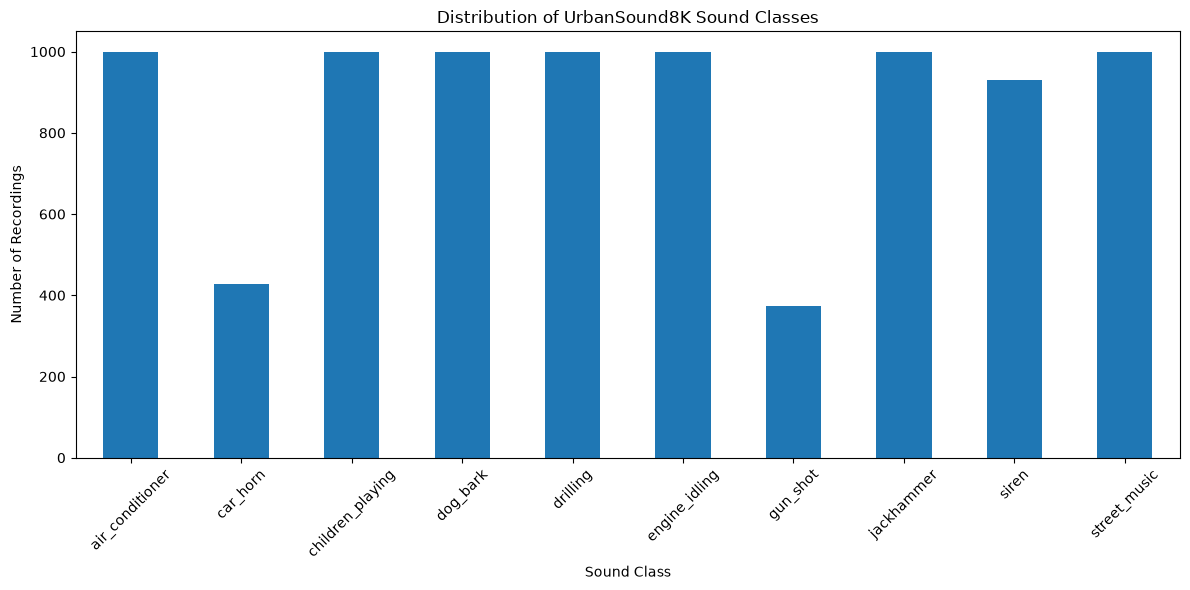

In [3]:
class_counts = df["class"].value_counts().sort_index()

print("Number of recordings per sound class:")
display(class_counts)

plt.figure(figsize=(12, 6))
class_counts.plot(kind="bar")

plt.title("Distribution of UrbanSound8K Sound Classes")
plt.xlabel("Sound Class")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Audio Properties Audio Properties Analysis

We analyzed all 8,732 WAV recordings across the 10 folds.

We inspected:
- Sampling rates
- Number of audio channels
- Recording durations
- Maximum signal amplitudes

The analysis shows that audio recordings have different technical properties. Therefore, preprocessing is necessary before CNN training.

In [10]:
audio_df = pd.read_csv(ROOT / "metadata/audio_properties.csv")

print("Total recordings analyzed:", len(audio_df))

print("\nSampling rate distribution:")
display(audio_df["sampling_rate"].value_counts())

print("\nChannel distribution:")
display(audio_df["channels"].value_counts())

print("\nDuration statistics:")
display(audio_df["duration"].describe())

print("\nAmplitude statistics:")
display(audio_df["amplitude"].describe())

Total recordings analyzed: 8732

Sampling rate distribution:


sampling_rate
44100     5370
48000     2502
96000      610
24000       82
16000       45
22050       44
11025       39
192000      17
8000        12
11024        7
32000        4
Name: count, dtype: int64


Channel distribution:


channels
2    7993
1     739
Name: count, dtype: int64


Duration statistics:


count    8732.000000
mean        3.607522
std         0.974394
min         0.050000
25%         4.000000
50%         4.000000
75%         4.000000
max         4.036647
Name: duration, dtype: float64


Amplitude statistics:


count    8732.000000
mean        0.478637
std         0.310304
min         0.001085
25%         0.201671
50%         0.430905
75%         0.726623
max         1.000000
Name: amplitude, dtype: float64

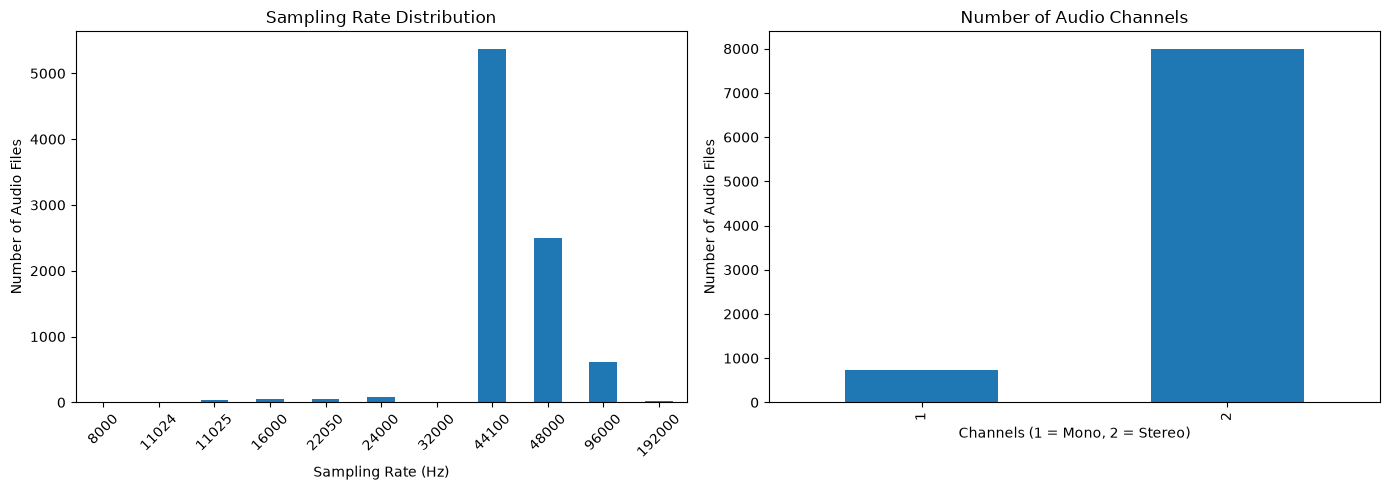

In [11]:
# Visualize audio properties

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sampling rate distribution
audio_df["sampling_rate"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Sampling Rate Distribution")
axes[0].set_xlabel("Sampling Rate (Hz)")
axes[0].set_ylabel("Number of Audio Files")
axes[0].tick_params(axis="x", rotation=45)

# Channel distribution
audio_df["channels"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Number of Audio Channels")
axes[1].set_xlabel("Channels (1 = Mono, 2 = Stereo)")
axes[1].set_ylabel("Number of Audio Files")

plt.tight_layout()
plt.show()

duration histogram

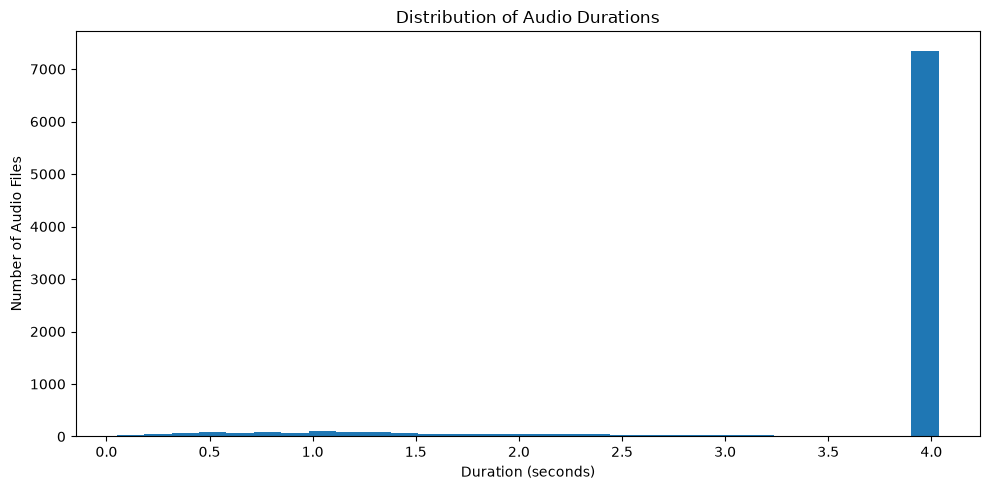

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(audio_df["duration"], bins=30)

plt.title("Distribution of Audio Durations")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Audio Files")

plt.tight_layout()
plt.show()

amplitude histogram

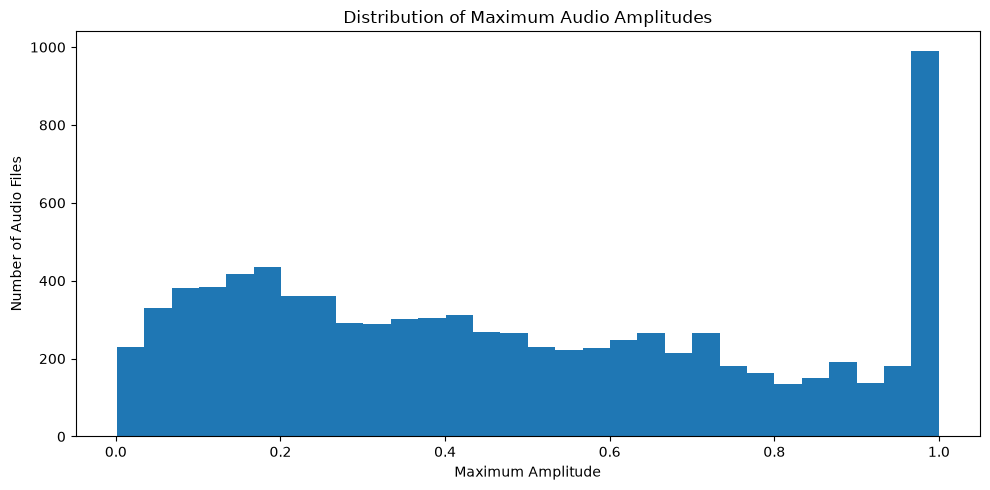

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(audio_df["amplitude"], bins=30)

plt.title("Distribution of Maximum Audio Amplitudes")
plt.xlabel("Maximum Amplitude")
plt.ylabel("Number of Audio Files")

plt.tight_layout()
plt.show()

### Observations

- Most recordings have a duration close to 4 seconds.
- Some recordings are shorter, so padding is necessary.
- Audio amplitudes vary between recordings.
- Normalization helps bring audio signals to a consistent amplitude range.

## Audio Preprocessing Audio Preprocessing

Audio recordings have different sampling rates, durations and channels.

To prepare them for CNN training, we apply the following steps:

1. Resample audio to 22,050 Hz.
2. Convert stereo audio to mono.
3. Crop or pad audio to 4 seconds.
4. Normalize the audio amplitude.

In [4]:
from src.audio_preprocessing import preprocess_audio

audio_path = os.path.join(
    DATASET_PATH,
    "fold1",
    "101415-3-0-2.wav"
)

if not os.path.isfile(audio_path):
    audio_path = DATASET_PATH / "audio/fold1/101415-3-0-2.wav"
processed_audio = preprocess_audio(audio_path)

print("Sampling rate: 22050 Hz")
print("Number of samples:", len(processed_audio))
print("Duration:", len(processed_audio) / 22050, "seconds")
print("Maximum amplitude:", np.max(np.abs(processed_audio)))

Sampling rate: 22050 Hz
Number of samples: 88200
Duration: 4.0 seconds
Maximum amplitude: 1.0


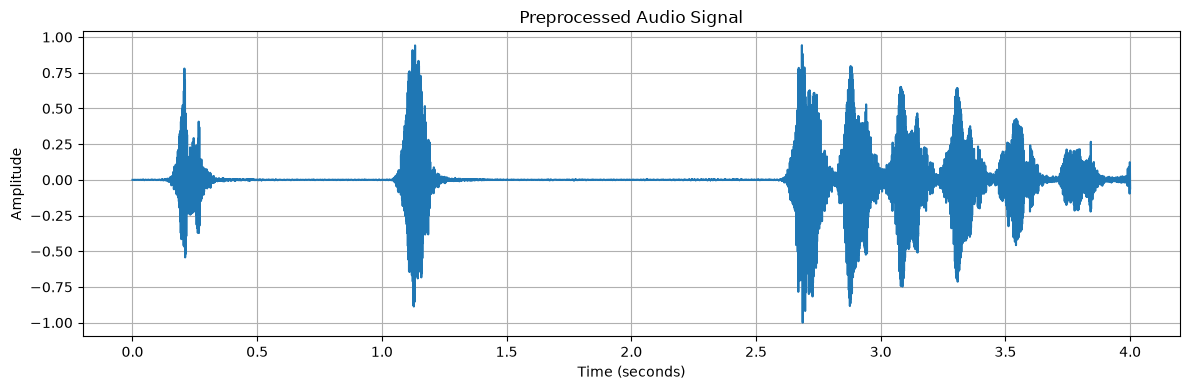

In [5]:
plt.figure(figsize=(12, 4))

time = np.arange(len(processed_audio)) / 22050

plt.plot(time, processed_audio)

plt.title("Preprocessed Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

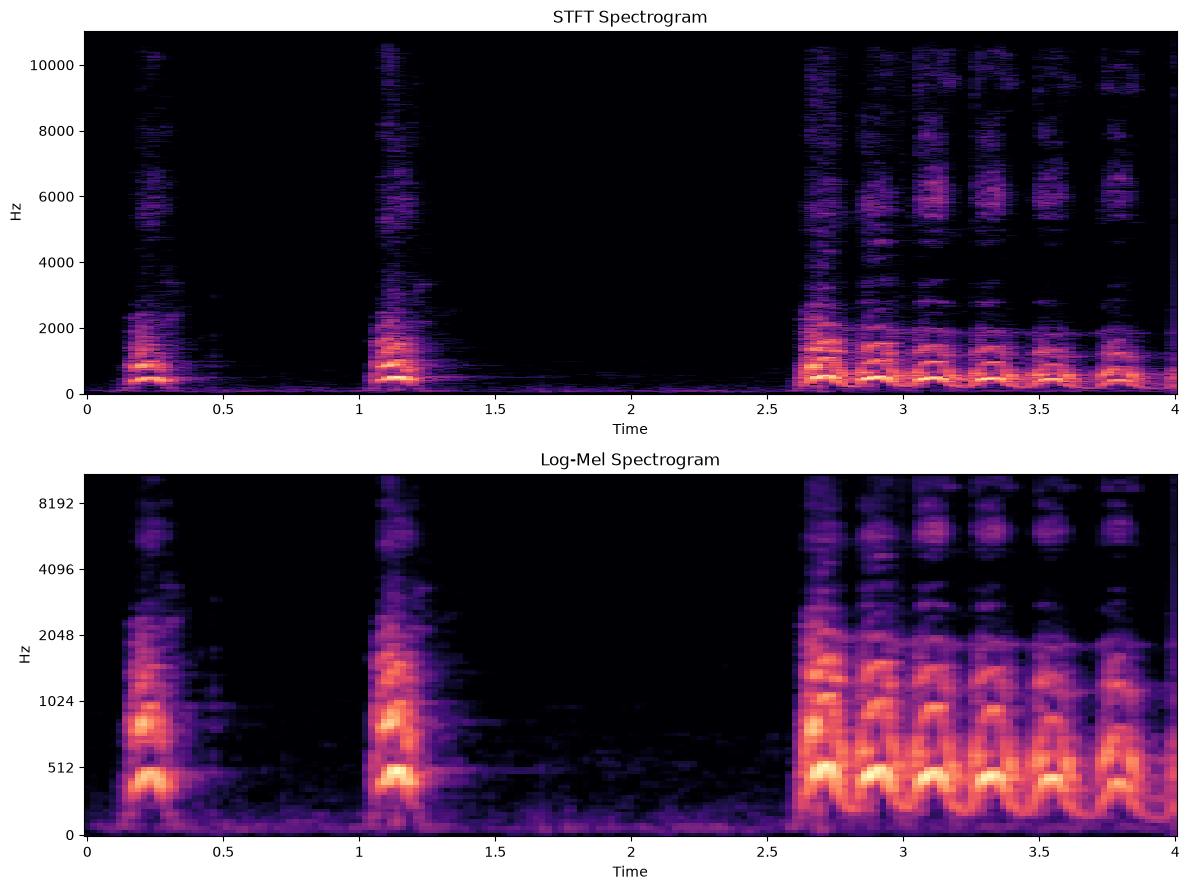

STFT shape: (1025, 173)
Log-Mel shape: (128, 173)
Both spectrograms generated successfully!
Spectrogram functions imported successfully!


In [6]:
from src.spectrograms import visualize_spectrograms
stft_db, mel_db = visualize_spectrograms(processed_audio)
print("STFT shape:", stft_db.shape)
print("Log-Mel shape:", mel_db.shape)

print("Spectrogram functions imported successfully!")

## Spectrogram Visualization

We generated two audio representations:

- STFT: Shows frequency changes over time.
- Log-Mel: Represents sound frequencies using the Mel scale.

The following figure compares both representations.

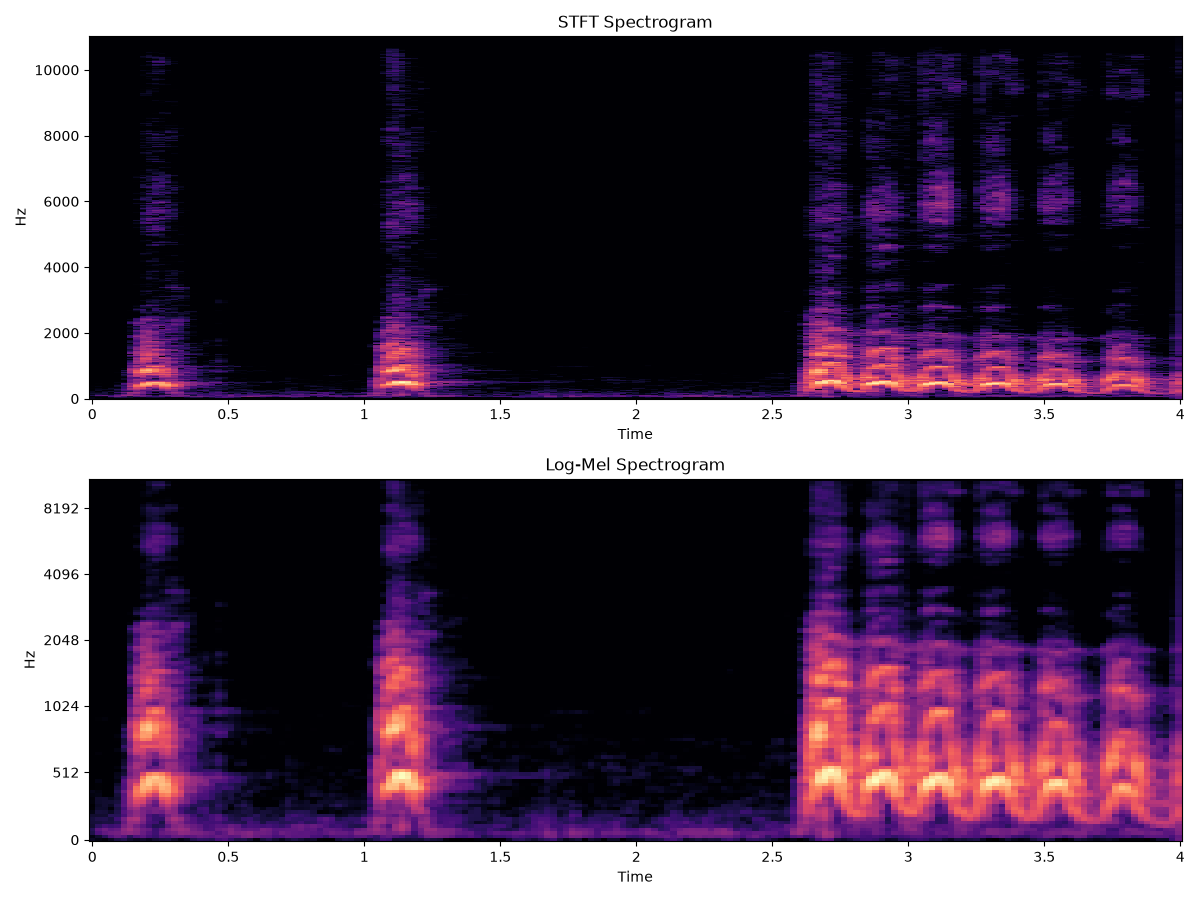

In [8]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / "figures/spectrogram_comparison.png")))

## Reusable Dataset Loader

The data loader prepares audio recordings for CNN training.

It performs the following operations:
- Loads audio files.
- Resamples and converts audio to mono.
- Adjusts recordings to 4 seconds.
- Generates Log-Mel spectrograms.
- Assigns a numerical label to each sound class.

In [9]:
from src.data_loader import load_data, CLASS_NAMES

# Load one fold for demonstration
X, y = load_data(folds=(1,))

print("Dataset loaded successfully!")
print("Input shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of samples:", len(X))

print("\nFirst 5 labels:")
for label in y[:5]:
    print(label, "=", CLASS_NAMES[label])

print("\nMinimum value:", X.min())
print("Maximum value:", X.max())

Dataset loaded successfully!
Input shape: (873, 128, 173, 1)
Labels shape: (873,)
Number of samples: 873

First 5 labels:
3 = dog_bark
3 = dog_bark
3 = dog_bark
3 = dog_bark
6 = gun_shot

Minimum value: 0.0
Maximum value: 1.0
